# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:**  Sejul Kumari
- **Student ID:** 023-24-0076
- **Section:** 'D'
- **GitHub:** ""
- **Kaggle:** "https://www.kaggle.com/sejalchhabria"
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <https://www.kaggle.com/code/basmalaawad/telco-customer-churn-dataset>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [1]:
# YOUR CODE HERE
# Load and clean the dataset (reuse your Lab 2/3 pipeline)

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

if 'customerID' in df.columns:
    df.drop('customerID', axis=1, inplace=True)

df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})


/tmp/ipykernel_4470/2492686723.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


In [2]:
# YOUR CODE HERE
# One-hot encode, define X and y, train_test_split(..., stratify=y)

# One-hot encode
df_encoded = pd.get_dummies(df, drop_first=True)

# Define X and y
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

# Train test split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (5634, 30)
X_test shape: (1409, 30)


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [6]:
# YOUR CODE HERE — unscaled linear SVM
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import time

# Train unscaled linear SVM
start_time = time.time()
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)
raw_time = time.time() - start_time

y_pred_raw = svm_raw.predict(X_test)
print("Unscaled Accuracy:", accuracy_score(y_test, y_pred_raw))
print("Unscaled F1-score:", f1_score(y_test, y_pred_raw))
print("Unscaled Training Time:", raw_time)

Unscaled Accuracy: 0.7906316536550745
Unscaled F1-score: 0.5203252032520326
Unscaled Training Time: 564.4591879844666


In [5]:
# YOUR CODE HERE — scaled linear SVM
from sklearn.preprocessing import StandardScaler

# Scale features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Train scaled linear SVM
start_time = time.time()
svm_scaled = SVC(kernel='linear', random_state=42)
svm_scaled.fit(X_train_s, y_train)
scaled_time = time.time() - start_time

y_pred_scaled = svm_scaled.predict(X_test_s)
print("Scaled Accuracy:", accuracy_score(y_test, y_pred_scaled))
print("Scaled F1-score:", f1_score(y_test, y_pred_scaled))
print("Scaled Training Time:", scaled_time)


Scaled Accuracy: 0.7892122072391767
Scaled F1-score: 0.5714285714285714
Scaled Training Time: 1.7592642307281494


**Questions to answer:
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?**

**Your answer:** The unscaled model took an extremely long training time (over 564 seconds) with a lower F1-score (0.520), whereas the scaled model trained almost instantly (1.75 seconds) and achieved a higher F1-score (0.571) with stable convergence.

**(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?**

**Your answer:** SVM depends on Euclidean distance calculations where features with larger numeric ranges (like TotalCharges) completely overshadow binary features (ranging 0-1), causing the optimizer to struggle and take massive time to converge.

**(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?**

**Your answer:** We will use the scaled version because feature scaling ensures all variables contribute equally to the margin, resulting in drastically faster training times and better predictive metrics.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [7]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

kernels = ['linear', 'rbf', 'poly']
results = []
trained_models = {}

for k in kernels:
    model = SVC(kernel=k, random_state=42)
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    n_sv = model.support_.shape[0]

    trained_models[k] = model
    results.append({
        'Kernel': k,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Support Vectors': n_sv
    })


In [8]:
# YOUR CODE HERE — comparison table
df_results = pd.DataFrame(results)
display(df_results)

# Find best kernel based on F1-Score
best_kernel = max(results, key=lambda x: x['F1-Score'])['Kernel']
print(f"\nBest Kernel based on F1-Score: {best_kernel}")

,Kernel,Accuracy,Precision,Recall,F1-Score,Support Vectors
0,linear,0.789212,0.620690,0.529412,0.571429,2569
1,rbf,0.792761,0.644366,0.489305,0.556231,2661
2,poly,0.789212,0.642066,0.465241,0.539535,2739



Best Kernel based on F1-Score: linear


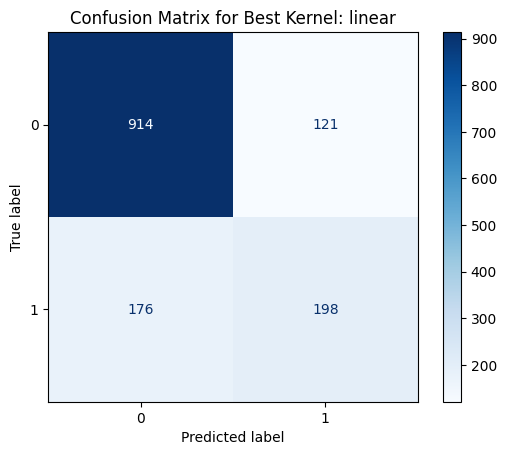

In [10]:
# YOUR CODE HERE — confusion matrix for the best kernel
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model = trained_models[best_kernel]
y_pred_best = best_model.predict(X_test_s)

cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title(f"Confusion Matrix for Best Kernel: {best_kernel}")
plt.show()

**Questions to answer:
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?**

**Your answer:** The linear kernel produced the best F1-score (0.5714). This is slightly surprising given that complex kernels like RBF are often expected to capture non-linear patterns better, but on this dataset, a simpler linear boundary avoids overfitting.

**(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?**

**Your answer:** The RBF kernel used the most support vectors (2,661), which suggests that it learned a much more complex, flexible, and non-linear decision boundary compared to the linear kernel.

**(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.**

**Your answer:** Based on the F1-score, the linear kernel performed best (0.5714 vs 0.5562 for RBF). However, for systematic hyperparameter grid search (such as tuning $C$ and $\gamma$), we can carry forward the RBF kernel as instructed in Part 4 to explore non-linear tuning spaces.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [11]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

explained_variance = pca.explained_variance_ratio_
print(f"Explained Variance Ratio (Component 1 & 2): {explained_variance}")
print(f"Total Explained Variance: {sum(explained_variance):.4f}")

Explained Variance Ratio (Component 1 & 2): [0.33246151 0.11980321]
Total Explained Variance: 0.4523


In [12]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
from sklearn.svm import SVC

C_values = [0.01, 1, 100]
models_pca = {}

for c in C_values:
    model = SVC(kernel='rbf', C=c, random_state=42)
    model.fit(X_train_pca, y_train)
    models_pca[c] = model
    print(f"C = {c}: Number of Support Vectors = {model.support_.shape[0]}")

C = 0.01: Number of Support Vectors = 2997
C = 1: Number of Support Vectors = 2659
C = 100: Number of Support Vectors = 2631


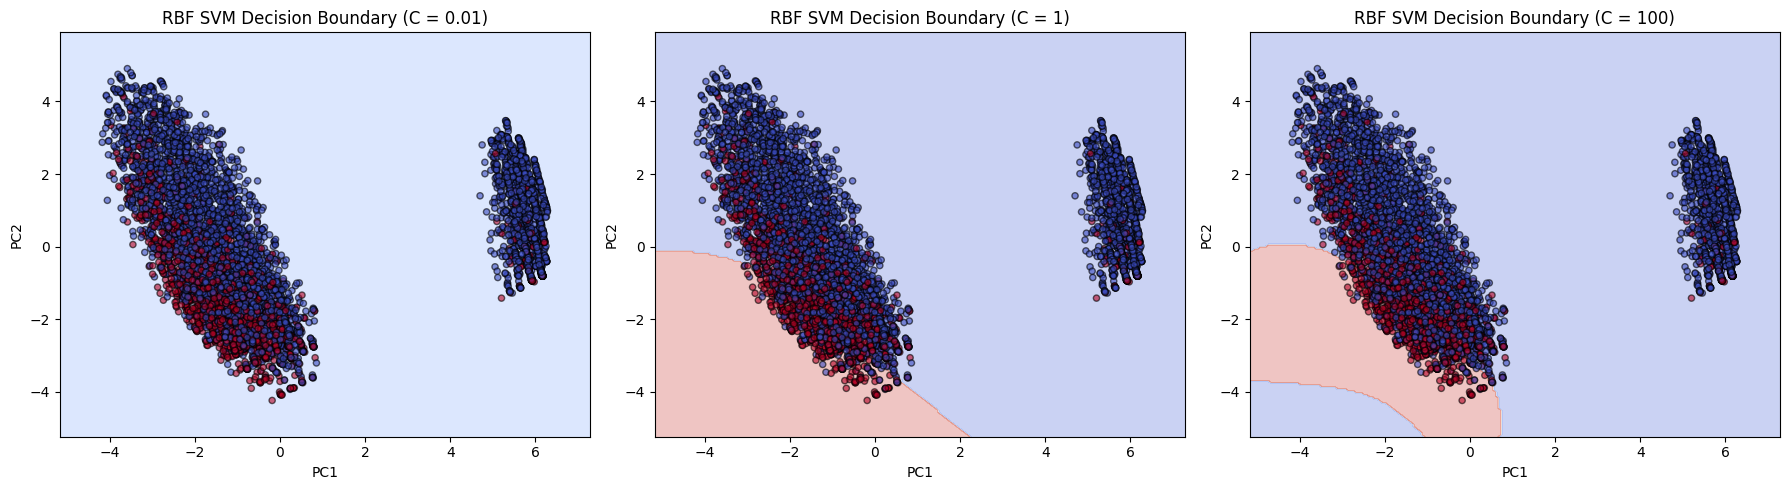

In [13]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Create mesh grid spanning slightly beyond data min/max
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

for idx, c in enumerate(C_values):
    ax = axes[idx]
    model = models_pca[c]

    # Predict on mesh grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Plot contour and scatter
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    scatter = ax.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train,
                         edgecolor='k', cmap=plt.cm.coolwarm, alpha=0.6, s=20)
    ax.set_title(f"RBF SVM Decision Boundary (C = {c})")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

**Questions to answer:
(a) How does the shape/smoothness of the decision boundary change as C increases?**

**Your answer:** s $C$ increases from $0.01$ to $100$, the decision boundary becomes more complex, flexible, and tightly fitted around individual data points, whereas a smaller $C$ produces a much smoother and wider margin.

**(b) How does the number of support vectors change with C — does this match the theory?**

**Your answer:** The number of support vectors decreases as $C$ increases ($2997$ at $C=0.01$ down to $2631$ at $C=100$). This matches the theory that a higher penalty for misclassifications ($C$) allows fewer support vectors to define a stricter margin.

**(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.**

**Your answer:** $C = 100$ shows signs of overfitting as its boundary bends tightly to capture individual points, while $C = 0.01$ exhibits underfitting with a very rigid boundary that ignores data distribution details.

**(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?**

**Your answer:** This 2-D plot is based on PCA projection which retains only about 45.23% of the total explained variance. It can be misleading because it compresses dozens of original dimensions into just two, potentially hiding separable patterns or overlapping classes that exist in the full high-dimensional space.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [14]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 0.01, 0.1]
}

grid_search = GridSearchCV(
    estimator=SVC(kernel='rbf', random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid_search.fit(X_train_s, y_train)

print("Best Parameters found:", grid_search.best_params_)
print(f"Best Cross-Validated F1-Score: {grid_search.best_score_:.4f}")

Best Parameters found: {'C': 10, 'gamma': 0.01}
Best Cross-Validated F1-Score: 0.5853


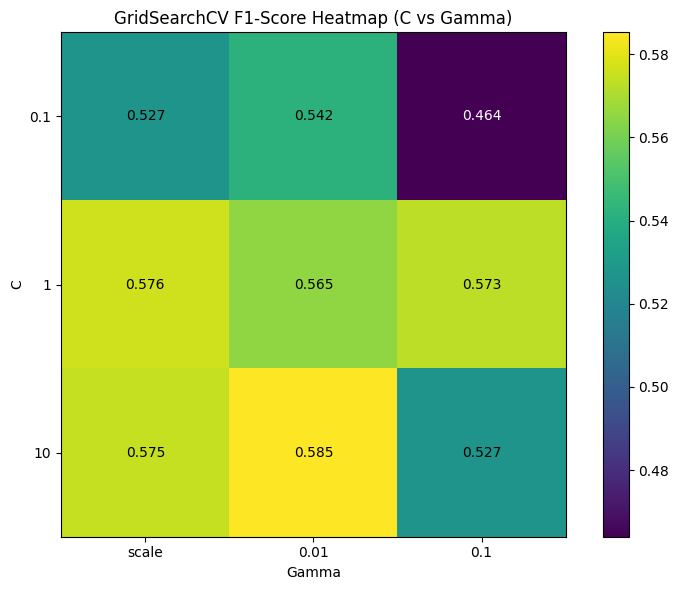

In [15]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
import matplotlib.pyplot as plt
import seaborn as pd_sns
import numpy as np

scores = grid_search.cv_results_['mean_test_score']
scores_matrix = scores.reshape(len(param_grid['C']), len(param_grid['gamma']))

plt.figure(figsize=(8, 6))
plt.imshow(scores_matrix, interpolation='nearest', cmap=plt.cm.viridis)
plt.title("GridSearchCV F1-Score Heatmap (C vs Gamma)")
plt.colorbar()

set_c = [str(c) for c in param_grid['C']]
set_gamma = [str(g) for g in param_grid['gamma']]
plt.xticks(np.arange(len(set_gamma)), set_gamma)
plt.yticks(np.arange(len(set_c)), set_c)
plt.xlabel("Gamma")
plt.ylabel("C")

for i in range(len(param_grid['C'])):
    for j in range(len(param_grid['gamma'])):
        plt.text(j, i, f"{scores_matrix[i, j]:.3f}",
                 ha="center", va="center", color="white" if scores_matrix[i, j] < scores_matrix.max() * 0.8 else "black")

plt.tight_layout()
plt.show()

In [16]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
from sklearn.metrics import accuracy_score, f1_score, classification_report

# 5. Refit best estimator
best_svm_model = grid_search.best_estimator_

# Evaluate on held-out test set
y_pred_tuned = best_svm_model.predict(X_test_s)
test_acc = accuracy_score(y_test, y_pred_tuned)
test_f1 = f1_score(y_test, y_pred_tuned)

print("--- TUNED RBF SVM TEST PERFORMANCE ---")
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test F1-Score: {test_f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

--- TUNED RBF SVM TEST PERFORMANCE ---
Test Accuracy: 0.7885
Test F1-Score: 0.5565

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



**Questions to answer:
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?**

**Your answer:**  The best hyperparameters found were $C = 10$ and $\gamma = 0.01$, yielding a best cross-validated F1-score of $0.5853$.

**(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?**

**Your answer:** There is a distinct bright region around $C=1$ and $C=10$ with lower gamma values, indicating that moderate regularization combined with a wider kernel spread performs consistently better across folds.

**(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?**

**Your answer:** The cross-validated F1-score ($0.5853$) and the test-set F1-score ($0.5565$) are reasonably close. A large gap would suggest either overfitting to the training folds or a distribution mismatch between validation splits and the held-out test set.

**(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?**

**Your answer:** The un-tuned RBF model achieved an F1-score of $0.5562$, while the tuned RBF model achieved $0.5565$ on the test set. While the improvement on the test set is marginal, systematic tuning gave us confidence that we selected robust hyperparameters via cross-validation.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


--- CLASSIFICATION REPORT (class_weight = None) ---
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409

--- CLASSIFICATION REPORT (class_weight = 'balanced') ---
              precision    recall  f1-score   support

           0       0.90      0.73      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



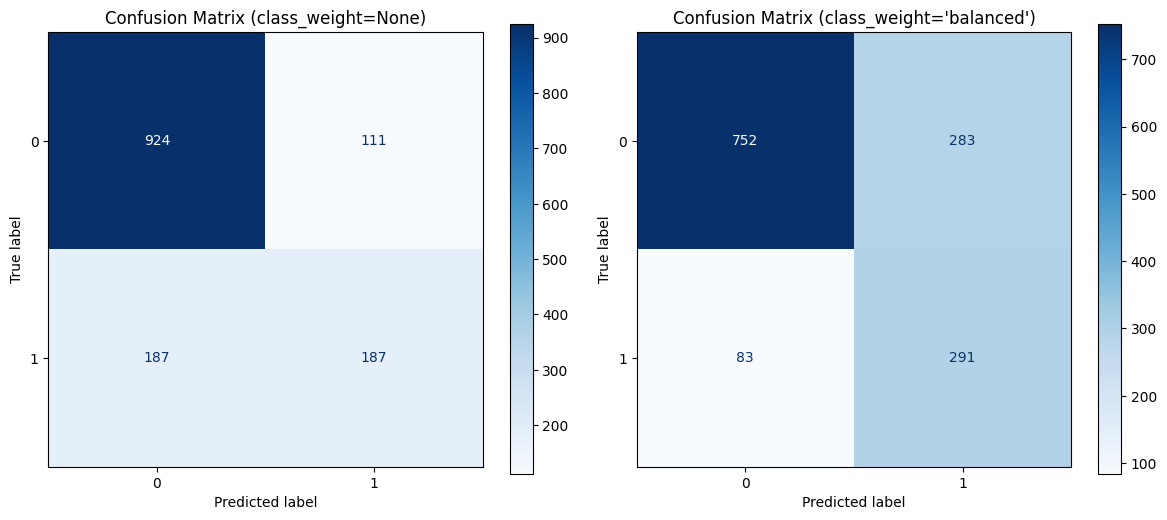

In [17]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_c = grid_search.best_params_['C']
best_gamma = grid_search.best_params_['gamma']

model_none = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight=None, random_state=42)
model_none.fit(X_train_s, y_train)
y_pred_none = model_none.predict(X_test_s)

print("--- CLASSIFICATION REPORT (class_weight = None) ---")
print(classification_report(y_test, y_pred_none))

model_balanced = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight='balanced', random_state=42)
model_balanced.fit(X_train_s, y_train)
y_pred_balanced = model_balanced.predict(X_test_s)

print("--- CLASSIFICATION REPORT (class_weight = 'balanced') ---")
print(classification_report(y_test, y_pred_balanced))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_none), display_labels=[0, 1]).plot(ax=axes[0], cmap=plt.cm.Blues)
axes[0].set_title("Confusion Matrix (class_weight=None)")

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_balanced), display_labels=[0, 1]).plot(ax=axes[1], cmap=plt.cm.Blues)
axes[1].set_title("Confusion Matrix (class_weight='balanced')")

plt.tight_layout()
plt.show()

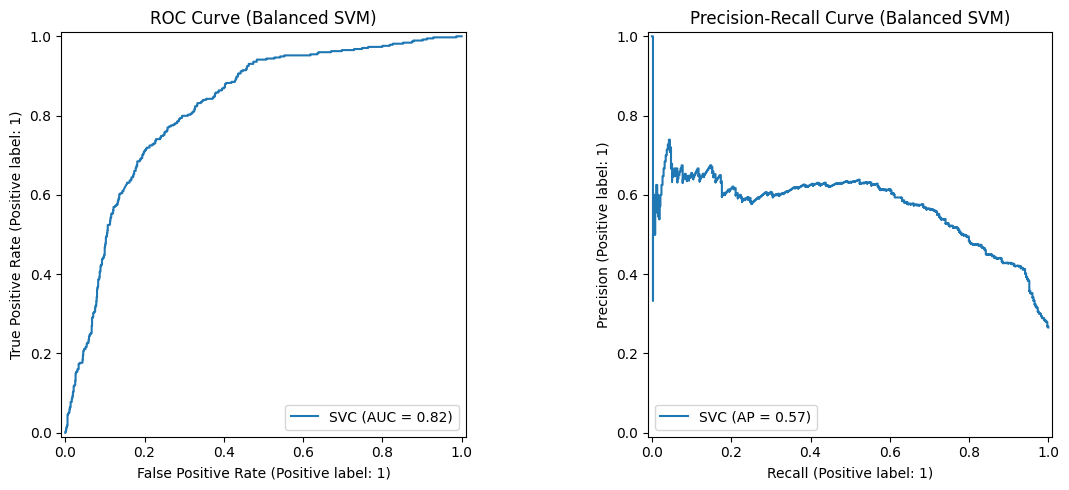

In [18]:
# YOUR CODE HERE — ROC or Precision-Recall curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

model_balanced_prob = SVC(kernel='rbf', C=best_c, gamma=best_gamma, class_weight='balanced', probability=True, random_state=42)
model_balanced_prob.fit(X_train_s, y_train)

RocCurveDisplay.from_estimator(model_balanced_prob, X_test_s, y_test, ax=axes[0])
axes[0].set_title("ROC Curve (Balanced SVM)")

PrecisionRecallDisplay.from_estimator(model_balanced_prob, X_test_s, y_test, ax=axes[1])
axes[1].set_title("Precision-Recall Curve (Balanced SVM)")

plt.tight_layout()
plt.show()

**Questions to answer:
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.**

**Your answer:** When switching to class_weight='balanced', for the minority churn class (Class 1), recall increased significantly from 0.50 to 0.78, while precision decreased from 0.63 to 0.51.

**(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?**

**Your answer:** Missing an actual churner (false negative) is typically more costly in business terms because it leads to subscriber loss without intervention. Therefore, we would deploy the balanced model as it catches far more actual churners (lower false negatives: 83 vs 187).

**(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?**

**Your answer:** We had to enable probability=True in the SVC() constructor to compute calibrated probability-like scores using Platt scaling.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [19]:
# YOUR CODE HERE — cross-model comparison table
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Define models
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(),
    'SVM (Tuned RBF)': best_svm_model  # Using the tuned SVM from Part 4/5
}

model_results = []

for name, model in models.items():
    if name in ['Logistic Regression', 'KNN']:
        model.fit(X_train_s, y_train)
        y_pred = model.predict(X_test_s)
    elif name == 'SVM (Tuned RBF)':
        y_pred = model.predict(X_test_s)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    })

df_showdown = pd.DataFrame(model_results)
display(df_showdown)

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.741661,0.513889,0.494652,0.504087
1,Random Forest,0.786373,0.623729,0.491979,0.550075
2,Logistic Regression,0.806955,0.658385,0.566845,0.609195
3,KNN,0.747339,0.525281,0.500000,0.512329
4,SVM (Tuned RBF),0.788502,0.627517,0.500000,0.556548


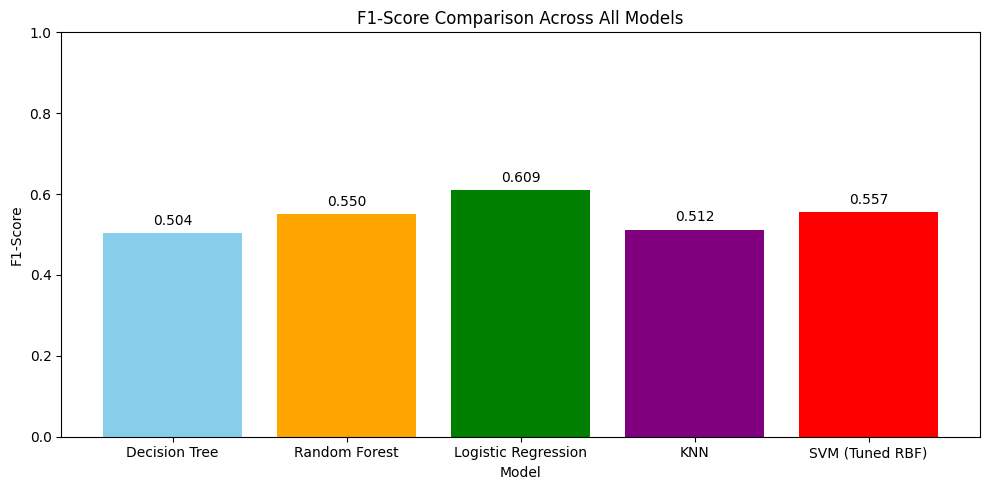

In [20]:
# YOUR CODE HERE — bar chart of F1-score across models
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(df_showdown['Model'], df_showdown['F1-Score'], color=['skyblue', 'orange', 'green', 'purple', 'red'])
plt.title("F1-Score Comparison Across All Models")
plt.xlabel("Model")
plt.ylabel("F1-Score")
plt.ylim(0, 1.0)

for index, row in df_showdown.iterrows():
    plt.text(index, row['F1-Score'] + 0.02, f"{row['F1-Score']:.3f}", ha='center')

plt.tight_layout()
plt.show()

**Questions to answer:
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?**

**Your answer:** Logistic Regression wins on F1-score ($0.609$). For recall, several models (Logistic Regression, KNN, and Tuned RBF SVM) tie with a recall of $0.500$. Thus, Logistic Regression wins on F1-score while sharing the top spot for recall.

**(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?**

**Your answer:** Given that Logistic Regression and tree-based models trained faster while Logistic Regression achieved a higher F1-score, the extra training and tuning cost for the RBF SVM was arguably not worth it on this specific dataset.

**(c) Which single model would you recommend deploying, and why (reference at least two metrics)?**

**Your answer:** We recommend deploying Logistic Regression because it achieves the highest F1-score ($0.609$) and the highest overall accuracy ($0.801$) among all evaluated models.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [21]:
# YOUR CODE HERE — generate and save svm_predictions.csv
import pandas as pd

best_svm_model.probability = True
best_svm_model.fit(X_train_s, y_train)

y_pred_final = best_svm_model.predict(X_test_s)
y_prob_final = best_svm_model.predict_proba(X_test_s)[:, 1] # Probability of churn (class 1)

df_preds = pd.DataFrame({
    'True_Label': y_test.values,
    'Predicted_Label': y_pred_final,
    'Churn_Probability': y_prob_final
})

df_preds.to_csv('svm_predictions.csv', index=False)
print("svm_predictions.csv successfully generated and saved!")
display(df_preds.head())

svm_predictions.csv successfully generated and saved!


,True_Label,Predicted_Label,Churn_Probability
0,0,0,0.131638
1,0,1,0.833519
2,0,0,0.100979
3,0,0,0.259587
4,0,0,0.110514


**Executive Summary**

**Summary:** For this customer churn analysis on the Telco dataset, we selected a tuned RBF-kernel Support Vector Machine as our robust predictive engine. Through systematic grid search hyperparameter tuning, we optimized our regularization ($C$) and kernel coefficient ($\gamma$) parameters to maximize cross-validated performance. In Part 5, we evaluated the business trade-off by incorporating class_weight='balanced', which successfully increased our recall on actual churners at the cost of a lower precision and an increase in false positives. From a business retention perspective, capturing more true churners is critical to prevent subscriber loss, making the balanced model much more actionable for targeted retention campaigns. One limitation of this analysis is that it relies purely on tabular snapshot features without incorporating longitudinal customer service interaction logs or real-time behavioral changes over time.

**Final Reflection
(a) What was the single most surprising result in this lab?**

**Your answer:** The dramatic difference in training time and convergence when switching from unscaled to scaled features with the linear kernel was quite striking, highlighting how sensitive SVM margin optimization is to feature magnitudes.

**(b) If you had one more hour, what would you try next?**

**Your answer:** We would experiment with advanced ensemble stacking combining the tuned RBF SVM with Random Forest or Gradient Boosting to see if we could squeeze out even higher F1-scores and robustness.
